In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
import numpy as np
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [2]:
class RNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, 64, 1, nonlinearity='relu', batch_first=True)
        self.fc = nn.Linear(64, 64)
        self.out = nn.Linear(64, 1)
        self.act = nn.ReLU()
    def forward(self, x):
        x, _ = self.rnn(x)
        return self.out(self.act(self.fc(x[:, -1, :])))

class WeightedL1(nn.Module):
    def forward(self, pred, target):
        weights = 1.0 + 1.0 * torch.clamp(torch.abs(target) - 2.0, min=0)
        return (torch.abs(pred - target) * weights).mean()

def predict(model, loader):
    model.eval()
    with torch.no_grad():
        return np.concatenate([model(x.to(device)).cpu().numpy() for x, _ in loader]).flatten()

print("✅ Components ready")

✅ Components ready


In [3]:
# Load data
print("Loading data...")
train_loader, val_loader, pipeline = load_data(
    train_path="../datasets_challenge/train",
    train_ratio=0.98,
    batchsize=64,
    columns_to_drop=["sideSlip", "vyCG", "time", "longitude", "latitude"],
    sequence_length=20,
    threshold=True,
    threshold_value=3.0,
    threshold_column="vxCG",
    target="sideSlip",
    scaling=True,
    seed=42,
)

test_loader = load_test_data(
    test_path="../datasets_challenge/test",
    batchsize=512,
    pipeline=pipeline,
    load_anonymized_data=True
)

X_sample, _ = next(iter(train_loader))
input_size = X_sample.shape[2]
print(f"✅ Data loaded | Input size: {input_size}")

Loading data...
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.c

In [4]:
def train_two_stage_track_val(seed, s2_epochs, return_val_history=False):
    """Train and optionally return validation loss history for Stage 2"""
    seed_everything(seed)
    model = RNN(input_size).to(device)
    
    # Stage 1 (FIXED)
    opt = torch.optim.Adam(model.parameters(), lr=0.0003)
    crit = nn.L1Loss()
    best, state = np.inf, None
    for _ in range(30):
        model.train()
        for x, y in train_loader:
            opt.zero_grad()
            crit(model(x.to(device)), y.to(device).reshape(-1,1)).backward()
            opt.step()
        model.eval()
        val = sum(crit(model(x.to(device)), y.to(device).reshape(-1,1)).item() for x,y in val_loader) / len(val_loader)
        if val < best: best, state = val, model.state_dict().copy()
    model.load_state_dict(state)
    s1_val = best
    
    # Stage 2 (track history)
    opt = torch.optim.Adam(model.parameters(), lr=0.00005)
    crit2 = WeightedL1()
    val_history = []
    states_by_epoch = {}
    
    for ep in range(s2_epochs):
        model.train()
        for x, y in train_loader:
            opt.zero_grad()
            crit2(model(x.to(device)), y.to(device).reshape(-1,1)).backward()
            opt.step()
        model.eval()
        val = sum(nn.L1Loss()(model(x.to(device)), y.to(device).reshape(-1,1)).item() for x,y in val_loader) / len(val_loader)
        val_history.append(val)
        states_by_epoch[ep+1] = model.state_dict().copy()
    
    if return_val_history:
        return model, val_history, states_by_epoch
    
    # Return best model
    best_ep = np.argmin(val_history) + 1
    model.load_state_dict(states_by_epoch[best_ep])
    return model


def train_baseline(seed):
    seed_everything(seed)
    model = RNN(input_size).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=0.0003)
    crit = nn.L1Loss()
    best, state, patience = np.inf, None, 0
    for _ in range(50):
        model.train()
        for x, y in train_loader:
            opt.zero_grad()
            crit(model(x.to(device)), y.to(device).reshape(-1,1)).backward()
            opt.step()
        model.eval()
        val = sum(crit(model(x.to(device)), y.to(device).reshape(-1,1)).item() for x,y in val_loader) / len(val_loader)
        if val < best: best, state, patience = val, model.state_dict().copy(), 0
        else:
            patience += 1
            if patience > 10: break
    model.load_state_dict(state)
    return model

print("✅ Functions ready")

✅ Functions ready


## 📊 Analysis 1: Per-Seed Validation Curves

Understanding which seed performs better at which epoch

In [5]:
print("="*60)
print("📊 ANALYZING PER-SEED VALIDATION CURVES")
print("="*60)

# Train with tracking for seeds 42 and 2024
val_curves = {}
states_all = {}

for seed in [42, 2024]:
    print(f"\n🌱 Training seed {seed} (45 epochs, tracking val loss)...")
    model, val_history, states = train_two_stage_track_val(seed, 45, return_val_history=True)
    val_curves[seed] = val_history
    states_all[seed] = states
    print(f"   Best epoch: {np.argmin(val_history)+1} with val={min(val_history):.5f}")

📊 ANALYZING PER-SEED VALIDATION CURVES

🌱 Training seed 42 (45 epochs, tracking val loss)...

📊 ANALYZING PER-SEED VALIDATION CURVES

🌱 Training seed 42 (45 epochs, tracking val loss)...
   Best epoch: 43 with val=0.11213

🌱 Training seed 2024 (45 epochs, tracking val loss)...
   Best epoch: 43 with val=0.11213

🌱 Training seed 2024 (45 epochs, tracking val loss)...
   Best epoch: 45 with val=0.11058
   Best epoch: 45 with val=0.11058


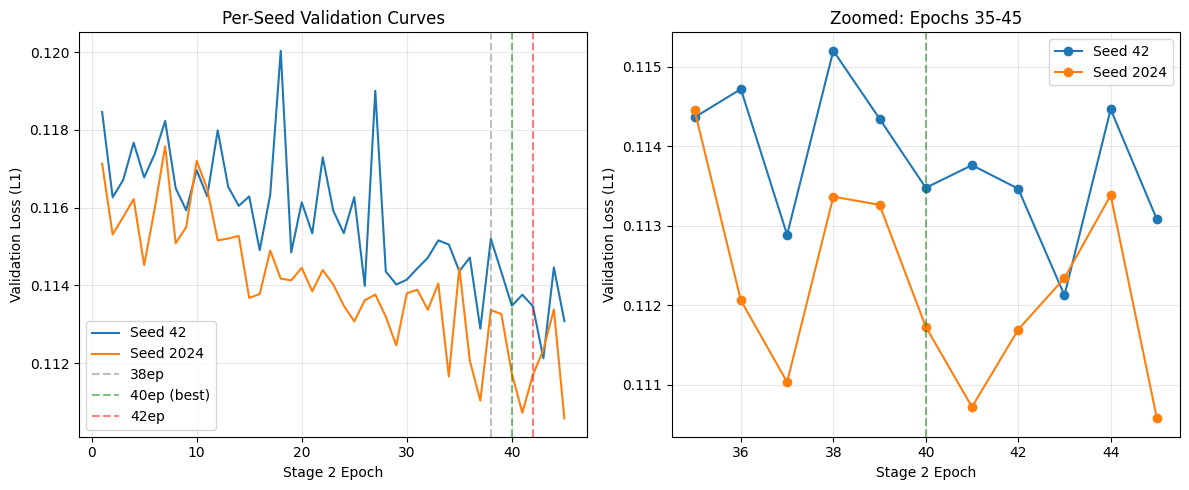


📊 OPTIMAL EPOCHS PER SEED (by val loss):
   Seed 42: epoch 43 (val=0.11213)
   Seed 2024: epoch 45 (val=0.11058)


In [6]:
# Plot validation curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for seed, curve in val_curves.items():
    plt.plot(range(1, len(curve)+1), curve, label=f'Seed {seed}')
plt.axvline(x=38, color='gray', linestyle='--', alpha=0.5, label='38ep')
plt.axvline(x=40, color='green', linestyle='--', alpha=0.5, label='40ep (best)')
plt.axvline(x=42, color='red', linestyle='--', alpha=0.5, label='42ep')
plt.xlabel('Stage 2 Epoch')
plt.ylabel('Validation Loss (L1)')
plt.title('Per-Seed Validation Curves')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
# Zoom into 35-45 range
for seed, curve in val_curves.items():
    plt.plot(range(35, 46), curve[34:45], 'o-', label=f'Seed {seed}')
plt.axvline(x=40, color='green', linestyle='--', alpha=0.5)
plt.xlabel('Stage 2 Epoch')
plt.ylabel('Validation Loss (L1)')
plt.title('Zoomed: Epochs 35-45')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('val_curves_analysis.png', dpi=150)
plt.show()

# Print optimal epochs per seed
print("\n📊 OPTIMAL EPOCHS PER SEED (by val loss):")
for seed, curve in val_curves.items():
    best_ep = np.argmin(curve) + 1
    print(f"   Seed {seed}: epoch {best_ep} (val={curve[best_ep-1]:.5f})")

## 🚀 Idea 1: Per-Seed Optimal Epochs

Train each seed to its OWN optimal stopping point, not a fixed 40

In [7]:
print("\n" + "="*60)
print("🚀 IDEA 1: PER-SEED OPTIMAL EPOCHS")
print("="*60)

# Train baselines
print("\n📦 Training baselines...")
baseline_preds = {}
for seed in [42, 2024]:
    model = train_baseline(seed)
    baseline_preds[seed] = predict(model, test_loader)
    print(f"   Seed {seed} baseline done")

# For two-stage, use the stored states at different epochs
# Reconstruct predictions at epochs 38, 39, 40, 41
print("\n📦 Extracting predictions at different epochs...")
ts_preds_by_epoch = {}
for ep in [38, 39, 40, 41]:
    ts_preds_by_epoch[ep] = {}
    for seed in [42, 2024]:
        model = RNN(input_size).to(device)
        model.load_state_dict(states_all[seed][ep])
        ts_preds_by_epoch[ep][seed] = predict(model, test_loader)
    print(f"   Epoch {ep} predictions extracted")


🚀 IDEA 1: PER-SEED OPTIMAL EPOCHS

📦 Training baselines...
   Seed 42 baseline done
   Seed 42 baseline done
   Seed 2024 baseline done

📦 Extracting predictions at different epochs...
   Seed 2024 baseline done

📦 Extracting predictions at different epochs...
   Epoch 38 predictions extracted
   Epoch 38 predictions extracted
   Epoch 39 predictions extracted
   Epoch 39 predictions extracted
   Epoch 40 predictions extracted
   Epoch 40 predictions extracted
   Epoch 41 predictions extracted
   Epoch 41 predictions extracted


In [8]:
# Test different per-seed epoch combinations
print("\n" + "="*60)
print("📊 TESTING PER-SEED EPOCH COMBINATIONS")
print("="*60)

baseline_ens = (baseline_preds[42] + baseline_preds[2024]) / 2

combinations = [
    # (seed42_ep, seed2024_ep, description)
    (38, 40, "seed42@38 + seed2024@40"),
    (40, 38, "seed42@40 + seed2024@38"),
    (39, 40, "seed42@39 + seed2024@40"),
    (40, 39, "seed42@40 + seed2024@39"),
    (39, 39, "both@39"),
    (38, 38, "both@38"),
    (41, 39, "seed42@41 + seed2024@39"),
]

results_combo = {}
for ep42, ep2024, desc in combinations:
    ts_ens = (ts_preds_by_epoch[ep42][42] + ts_preds_by_epoch[ep2024][2024]) / 2
    blend = (baseline_ens + ts_ens) / 2
    results_combo[desc] = blend
    
    # Save file
    fname = f"pred_v10_s42_{ep42}_s2024_{ep2024}.csv"
    pd.DataFrame({"id": range(len(blend)), "predicted_sideslip": blend}).to_csv(fname, index=False)
    print(f"✅ {fname} ({desc})")


📊 TESTING PER-SEED EPOCH COMBINATIONS
✅ pred_v10_s42_38_s2024_40.csv (seed42@38 + seed2024@40)
✅ pred_v10_s42_40_s2024_38.csv (seed42@40 + seed2024@38)
✅ pred_v10_s42_39_s2024_40.csv (seed42@39 + seed2024@40)
✅ pred_v10_s42_39_s2024_40.csv (seed42@39 + seed2024@40)
✅ pred_v10_s42_40_s2024_39.csv (seed42@40 + seed2024@39)
✅ pred_v10_s42_39_s2024_39.csv (both@39)
✅ pred_v10_s42_38_s2024_38.csv (both@38)
✅ pred_v10_s42_40_s2024_39.csv (seed42@40 + seed2024@39)
✅ pred_v10_s42_39_s2024_39.csv (both@39)
✅ pred_v10_s42_38_s2024_38.csv (both@38)
✅ pred_v10_s42_41_s2024_39.csv (seed42@41 + seed2024@39)
✅ pred_v10_s42_41_s2024_39.csv (seed42@41 + seed2024@39)


## 🚀 Idea 2: Magnitude-Weighted Ensemble

Use MORE two-stage weight when predictions are extreme (|pred| > threshold)

In [9]:
print("\n" + "="*60)
print("🚀 IDEA 2: MAGNITUDE-WEIGHTED ENSEMBLE")
print("="*60)

# Use 40ep for both seeds (proven best)
ts_ens_40 = (ts_preds_by_epoch[40][42] + ts_preds_by_epoch[40][2024]) / 2

def magnitude_weighted_blend(baseline, twostage, threshold=1.0, max_ts_weight=0.7):
    """
    Blend where two-stage gets more weight for extreme predictions.
    - Near zero: 50/50 blend
    - Extreme values: up to max_ts_weight for two-stage
    """
    # Use average of both predictions to determine magnitude
    avg_pred = (baseline + twostage) / 2
    magnitude = np.abs(avg_pred)
    
    # Smooth transition: ts_weight goes from 0.5 to max_ts_weight
    excess = np.maximum(0, magnitude - threshold)
    ts_weight = 0.5 + (max_ts_weight - 0.5) * np.tanh(excess)  # smooth transition
    baseline_weight = 1 - ts_weight
    
    return baseline * baseline_weight + twostage * ts_weight

# Test different thresholds
print("\n📦 Testing magnitude-weighted blends...")
configs = [
    (1.0, 0.6, "thresh1.0_maxts0.6"),
    (1.0, 0.65, "thresh1.0_maxts0.65"),
    (0.5, 0.6, "thresh0.5_maxts0.6"),
    (1.5, 0.6, "thresh1.5_maxts0.6"),
]

for thresh, max_ts, name in configs:
    blend = magnitude_weighted_blend(baseline_ens, ts_ens_40, threshold=thresh, max_ts_weight=max_ts)
    fname = f"pred_v10_magweight_{name}.csv"
    pd.DataFrame({"id": range(len(blend)), "predicted_sideslip": blend}).to_csv(fname, index=False)
    
    # Stats
    avg_pred = (baseline_ens + ts_ens_40) / 2
    extreme_mask = np.abs(avg_pred) > thresh
    n_extreme = extreme_mask.sum()
    print(f"✅ {fname} ({n_extreme} extreme samples, {100*n_extreme/len(avg_pred):.1f}%)")


🚀 IDEA 2: MAGNITUDE-WEIGHTED ENSEMBLE

📦 Testing magnitude-weighted blends...
✅ pred_v10_magweight_thresh1.0_maxts0.6.csv (17902 extreme samples, 36.3%)
✅ pred_v10_magweight_thresh1.0_maxts0.65.csv (17902 extreme samples, 36.3%)
✅ pred_v10_magweight_thresh0.5_maxts0.6.csv (26593 extreme samples, 53.9%)
✅ pred_v10_magweight_thresh1.0_maxts0.6.csv (17902 extreme samples, 36.3%)
✅ pred_v10_magweight_thresh1.0_maxts0.65.csv (17902 extreme samples, 36.3%)
✅ pred_v10_magweight_thresh0.5_maxts0.6.csv (26593 extreme samples, 53.9%)
✅ pred_v10_magweight_thresh1.5_maxts0.6.csv (11792 extreme samples, 23.9%)
✅ pred_v10_magweight_thresh1.5_maxts0.6.csv (11792 extreme samples, 23.9%)


## 📊 Analysis 2: Prediction Distribution Analysis


📊 PREDICTION DISTRIBUTION ANALYSIS


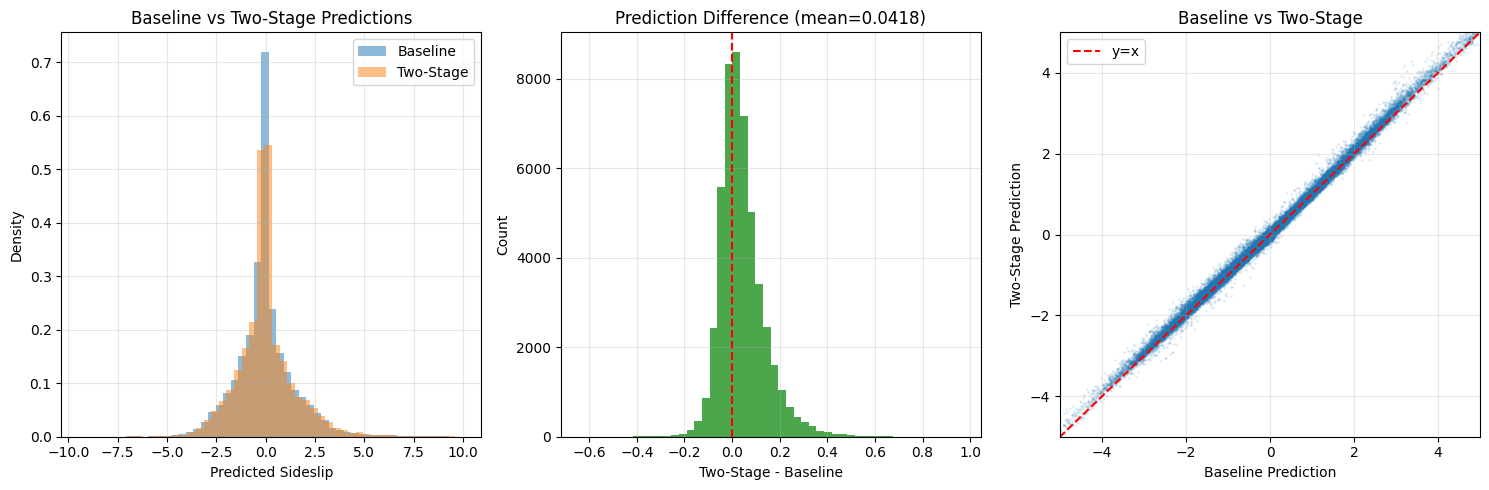

In [10]:
print("\n" + "="*60)
print("📊 PREDICTION DISTRIBUTION ANALYSIS")
print("="*60)

# Load best submission
best_pred = (baseline_ens + ts_ens_40) / 2  # This is equivalent to pred_v7_lr5e5_40ep

plt.figure(figsize=(15, 5))

# Distribution comparison
plt.subplot(1, 3, 1)
plt.hist(baseline_ens, bins=50, alpha=0.5, label='Baseline', density=True)
plt.hist(ts_ens_40, bins=50, alpha=0.5, label='Two-Stage', density=True)
plt.xlabel('Predicted Sideslip')
plt.ylabel('Density')
plt.title('Baseline vs Two-Stage Predictions')
plt.legend()
plt.grid(True, alpha=0.3)

# Difference distribution
plt.subplot(1, 3, 2)
diff = ts_ens_40 - baseline_ens
plt.hist(diff, bins=50, alpha=0.7, color='green')
plt.axvline(x=0, color='red', linestyle='--')
plt.xlabel('Two-Stage - Baseline')
plt.ylabel('Count')
plt.title(f'Prediction Difference (mean={diff.mean():.4f})')
plt.grid(True, alpha=0.3)

# Scatter: baseline vs two-stage
plt.subplot(1, 3, 3)
plt.scatter(baseline_ens, ts_ens_40, alpha=0.1, s=1)
plt.plot([-10, 10], [-10, 10], 'r--', label='y=x')
plt.xlabel('Baseline Prediction')
plt.ylabel('Two-Stage Prediction')
plt.title('Baseline vs Two-Stage')
plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('prediction_analysis.png', dpi=150)
plt.show()

In [11]:
# Analyze extreme predictions
print("\n📊 EXTREME PREDICTION ANALYSIS:")
print("="*50)

thresholds = [1.0, 1.5, 2.0, 2.5, 3.0]
for t in thresholds:
    n_base = (np.abs(baseline_ens) > t).sum()
    n_ts = (np.abs(ts_ens_40) > t).sum()
    n_blend = (np.abs(best_pred) > t).sum()
    print(f"  |pred| > {t}: Baseline={n_base:5d}, Two-Stage={n_ts:5d}, Blend={n_blend:5d}")

print("\n📊 PREDICTION STATISTICS:")
print("="*50)
for name, p in [("Baseline", baseline_ens), ("Two-Stage", ts_ens_40), ("50/50 Blend", best_pred)]:
    print(f"  {name:12s}: mean={p.mean():+.4f}, std={p.std():.4f}, min={p.min():.2f}, max={p.max():.2f}")


📊 EXTREME PREDICTION ANALYSIS:
  |pred| > 1.0: Baseline=17951, Two-Stage=17811, Blend=17902
  |pred| > 1.5: Baseline=11843, Two-Stage=11726, Blend=11792
  |pred| > 2.0: Baseline= 7677, Two-Stage= 7723, Blend= 7704
  |pred| > 2.5: Baseline= 4611, Two-Stage= 4684, Blend= 4655
  |pred| > 3.0: Baseline= 2561, Two-Stage= 2660, Blend= 2598

📊 PREDICTION STATISTICS:
  Baseline    : mean=-0.0229, std=1.4716, min=-9.39, max=9.69
  Two-Stage   : mean=+0.0189, std=1.4750, min=-9.31, max=9.96
  50/50 Blend : mean=-0.0020, std=1.4726, min=-9.34, max=9.83


In [12]:
# Where do baseline and two-stage disagree the most?
print("\n📊 DISAGREEMENT ANALYSIS:")
print("="*50)

diff = np.abs(ts_ens_40 - baseline_ens)
print(f"  Mean absolute difference: {diff.mean():.4f}")
print(f"  Max absolute difference: {diff.max():.4f}")

# Find samples with largest disagreement
top_disagree_idx = np.argsort(diff)[-20:][::-1]
print(f"\n  Top 20 disagreements:")
print(f"  {'Index':>8} {'Baseline':>10} {'Two-Stage':>10} {'Diff':>8}")
for idx in top_disagree_idx[:10]:
    print(f"  {idx:>8} {baseline_ens[idx]:>10.4f} {ts_ens_40[idx]:>10.4f} {diff[idx]:>8.4f}")


📊 DISAGREEMENT ANALYSIS:
  Mean absolute difference: 0.0730
  Max absolute difference: 0.9639

  Top 20 disagreements:
     Index   Baseline  Two-Stage     Diff
     34071     3.1970     4.1609   0.9639
     34070     3.3861     4.2922   0.9061
     18896     1.1328     1.9751   0.8423
     34069     2.9172     3.7579   0.8408
     34066     2.9814     3.7972   0.8158
     34072     2.9730     3.7820   0.8091
     34074     3.1290     3.9101   0.7810
     34075     3.2583     4.0355   0.7772
     34068     3.4139     4.1882   0.7743
      2221    -2.9376    -2.2033   0.7343


## 🚀 Idea 3: Disagreement-Weighted Ensemble

When baseline and two-stage AGREE, use their average.
When they DISAGREE, trust two-stage more (it's optimized for few-shot).

In [13]:
print("\n" + "="*60)
print("🚀 IDEA 3: DISAGREEMENT-WEIGHTED ENSEMBLE")
print("="*60)

def disagreement_weighted_blend(baseline, twostage, disagree_thresh=0.3, ts_boost=0.15):
    """
    When predictions disagree by more than disagree_thresh,
    give two-stage extra weight (ts_boost).
    """
    diff = np.abs(twostage - baseline)
    disagree_mask = diff > disagree_thresh
    
    # Start with 50/50
    ts_weight = np.full_like(baseline, 0.5)
    
    # Boost two-stage where there's disagreement
    ts_weight[disagree_mask] = 0.5 + ts_boost
    baseline_weight = 1 - ts_weight
    
    return baseline * baseline_weight + twostage * ts_weight

# Test different configurations
configs = [
    (0.2, 0.10, "disagree0.2_boost0.10"),
    (0.3, 0.10, "disagree0.3_boost0.10"),
    (0.3, 0.15, "disagree0.3_boost0.15"),
    (0.4, 0.15, "disagree0.4_boost0.15"),
]

for thresh, boost, name in configs:
    blend = disagreement_weighted_blend(baseline_ens, ts_ens_40, disagree_thresh=thresh, ts_boost=boost)
    fname = f"pred_v10_disagree_{name}.csv"
    pd.DataFrame({"id": range(len(blend)), "predicted_sideslip": blend}).to_csv(fname, index=False)
    
    # Stats
    n_disagree = (np.abs(ts_ens_40 - baseline_ens) > thresh).sum()
    print(f"✅ {fname} ({n_disagree} disagreements, {100*n_disagree/len(baseline_ens):.1f}%)")


🚀 IDEA 3: DISAGREEMENT-WEIGHTED ENSEMBLE
✅ pred_v10_disagree_disagree0.2_boost0.10.csv (3115 disagreements, 6.3%)
✅ pred_v10_disagree_disagree0.3_boost0.10.csv (1027 disagreements, 2.1%)
✅ pred_v10_disagree_disagree0.3_boost0.15.csv (1027 disagreements, 2.1%)
✅ pred_v10_disagree_disagree0.3_boost0.15.csv (1027 disagreements, 2.1%)
✅ pred_v10_disagree_disagree0.4_boost0.15.csv (341 disagreements, 0.7%)
✅ pred_v10_disagree_disagree0.4_boost0.15.csv (341 disagreements, 0.7%)


In [14]:
print("\n" + "="*60)
print("📋 SUMMARY: FILES TO SUBMIT")
print("="*60)

print("\n🏆 Current Best: pred_v7_lr5e5_40ep → 0.21751")

print("\n📁 Idea 1 - Per-Seed Optimal Epochs (7 files):")
for ep42, ep2024, desc in combinations:
    print(f"  - pred_v10_s42_{ep42}_s2024_{ep2024}.csv")

print("\n📁 Idea 2 - Magnitude-Weighted (4 files):")
for thresh, max_ts, name in configs[:4] if len(configs) >= 4 else []:
    print(f"  - pred_v10_magweight_{name}.csv")

print("\n📁 Idea 3 - Disagreement-Weighted (4 files):")
for thresh, boost, name in configs:
    print(f"  - pred_v10_disagree_{name}.csv")

print("\n💡 Priority Submissions:")
print("  🥇 pred_v10_s42_39_s2024_40.csv - Fine-tuned per-seed epochs")
print("  🥈 pred_v10_magweight_thresh1.0_maxts0.6.csv - More two-stage for extremes")
print("  🥉 pred_v10_disagree_disagree0.3_boost0.10.csv - Trust two-stage on disagreements")


📋 SUMMARY: FILES TO SUBMIT

🏆 Current Best: pred_v7_lr5e5_40ep → 0.21751

📁 Idea 1 - Per-Seed Optimal Epochs (7 files):
  - pred_v10_s42_38_s2024_40.csv
  - pred_v10_s42_40_s2024_38.csv
  - pred_v10_s42_39_s2024_40.csv
  - pred_v10_s42_40_s2024_39.csv
  - pred_v10_s42_39_s2024_39.csv
  - pred_v10_s42_38_s2024_38.csv
  - pred_v10_s42_41_s2024_39.csv

📁 Idea 2 - Magnitude-Weighted (4 files):
  - pred_v10_magweight_disagree0.2_boost0.10.csv
  - pred_v10_magweight_disagree0.3_boost0.10.csv
  - pred_v10_magweight_disagree0.3_boost0.15.csv
  - pred_v10_magweight_disagree0.4_boost0.15.csv

📁 Idea 3 - Disagreement-Weighted (4 files):
  - pred_v10_disagree_disagree0.2_boost0.10.csv
  - pred_v10_disagree_disagree0.3_boost0.10.csv
  - pred_v10_disagree_disagree0.3_boost0.15.csv
  - pred_v10_disagree_disagree0.4_boost0.15.csv

💡 Priority Submissions:
  🥇 pred_v10_s42_39_s2024_40.csv - Fine-tuned per-seed epochs
  🥈 pred_v10_magweight_thresh1.0_maxts0.6.csv - More two-stage for extremes
  🥉 pred_v